# Low-k spectrum of the covariance: a scaled linear model instead of the measured P(k)

**Question.** The Gaussian covariance of the fits (`bf.gaussian_cov_pk`) is a sum over the box's Fourier modes
$|\mathbf k| = 2\pi|\mathbf n|/L$, from the fundamental $k_f = 2\pi/L \approx 0.0063\,h\,{\rm Mpc}^{-1}$ up, and uses each sample's measured spectrum
there. The first lattice shells hold few modes (6, 12 and 8 at k = 0.0063, 0.0089, 0.0109 h/Mpc), so the measured power
on them scatters by tens of per cent around its expected value, in the same direction for every sample (they share the
box's large-scale modes). The covariance should use the expected spectrum. For Full, $b^2P_{\rm lin}+N$ describes the
measured spectrum at low k; for the split samples it lies below it, so here the model is scaled to each sample's own
spectrum. Do α, Σ and w change when the covariance uses the scaled model on the lowest shells instead of the measured
values?

**The model.** For a sample with bias $b$ (the bias of its covariance, from `bf.estimate_bias_independent`, as in
`desilike_fits`), the low-k model of `bf.spectrum_for_cov` is

$$
M(k)=b^2P_{\rm lin}(k)+N,
$$

with $P_{\rm lin}$ the linear spectrum and $N$ the excess of the measured spectrum $\hat P$ over linear theory,
$\hat P-b^2P_{\rm lin}$, averaged over $k$ in `n_win` (0.1–0.2 h/Mpc), each shell weighted by its number of modes.
On each lattice shell $k$, with $N_k$ modes (counting $\mathbf k$ and $-\mathbf k$), take the ratio $r_k=\hat P(k)/M(k)$. The scale
factor $A$ is its mode-weighted mean over a window $W$ of low k:

$$
\boxed{\;A=\frac{\sum_{k\in W}N_k\,r_k}{\sum_{k\in W}N_k}\;},\qquad
\sigma_A\simeq A\sqrt{\frac{2}{\sum_{k\in W}N_k}}
$$

($\sigma_A$: the error of $A$ if the modes are Gaussian. A shell has $N_k/2$ independent modes, so $r_k$ scatters by
$\sqrt{2/N_k}$ around its mean, and $N_k$ is the inverse-variance weight.) The spectrum of the covariance then is

$$
\boxed{\;P_{\rm cov}(k)=\begin{cases}A\,M(k), & k<k_{\rm model}\\[2pt] \hat P(k), & k\ge k_{\rm model}\end{cases}\;}
$$

with the measured spectrum above $k_{\rm model}$, as now (`desilike_fits` uses $\hat P$ at all k).

**How.** The settings and the fitting functions are those of `desilike_fits.ipynb`: its settings cell and the
function definitions of its section 2 are run here, so the run (`split_name`), bins, fit range, priors and fits are the
same. For each sample the covariance is built twice with the same `bf.gaussian_cov_pk`: from the spectra file, as in
`desilike_fits`, and from a copy of it whose values below `k_model` are replaced by $A\,M(k)$. Nothing in
`bao_fitting.py` changes. Both covariances are then used in the α fit, the Σ fit with its profile χ²(Σ) and the
Gaussian peak fit of `desilike_fits` section 2, and the results are compared (about 2 min per sample and covariance).

In [1]:
# the settings cell and the function definitions of section 2 of desilike_fits.ipynb, run here (same run and fits)
import os, json
HERE = os.getcwd()                                            # notebooks/exploratory/gaussian_covariance_checks
FITS_DIR = os.path.abspath(os.path.join(HERE, '..'))          # notebooks/exploratory, where desilike_fits lives
with open(os.path.join(FITS_DIR, 'desilike_fits.ipynb')) as fh:
    fits_cells = [''.join(c['source']) for c in json.load(fh)['cells'] if c['cell_type'] == 'code']
setup_src = next(c for c in fits_cells if c.startswith('import os, re, sys'))      # its settings cell
sec2_src = next(c for c in fits_cells if c.startswith('def desilike_theory'))     # its section 2
sec2_defs = sec2_src[:sec2_src.index('\nres = {}')]                              # the function definitions only
os.chdir(FITS_DIR)                     # desilike_fits finds the repository from its own folder
try:
    exec(setup_src)
finally:
    os.chdir(HERE)
exec(sec2_defs)
print(f"\nrun of desilike_fits: {split_name};  fitting functions of its section 2 loaded")

magnitude cut -20.8;  bin width 5.0 h^-1 Mpc;  fit range (50.0, 150.0) h^-1 Mpc;  monopole files cover (5.0, 200.0)
alpha fit: Sigma ~ N(7.78, 3) [Sigma_th = Zel'dovich prediction];  Sigma fit: flat (0.0, 16.0), profile chi2(Sigma) in steps of 0.5
covariance: bias from (40, 70) h^-1 Mpc;  P_cov = b^2 P_lin + N below k_lo = 0.0, measured above k_hi = 0.001 (N from k in (0.1, 0.2)), measured spectrum up to k = 2.893 (2 foldings, each level to 0.6 of its Nyquist), constant excess above, modes summed to k = 3.0
covariance at low k: A M(k) on the shells k < k_model = 0.05 h/Mpc, A from k in (0.0, 0.05) (section 1)
spectra file: pk_XISMU_box_mag-20.8_dist_fil_Q4.npz
figures: figures/desilike_fits/dist_fil_Q4_mag-20.8_bin5_fit50-150
split: quartiles of dist_fil;  boundaries 0, 3.653, 8.502, 15.06, 57.51
  Q1: 0 <= dist_fil < 3.653   (N = 1249969;  reference Full dil nQ, N = 1249969)
  Q2: 3.653 <= dist_fil < 8.502   (N = 1249968;  reference Full dil nQ, N = 1249969)
  Q3: 8.502 <= dist_fil < 

## 1. The scale factor A and the two covariances

Settings of this check: the samples, the window $W$ of $A$ and $k_{\rm model}$. The table gives each sample's $b$,
$1/\bar n$, $N$ and $A\pm\sigma_A$. Then, for both covariances, the ratio of the errors $\sigma_\xi=\sqrt{C_{ii}}$ in the
fit range.

In [2]:
# ---------------- settings of this check ----------------
check_samples = ['Full'] + Q          # samples to check (names as in desilike_fits)
A_window = (0.0, 0.04)                # [h/Mpc] window W of the scale factor A (from the fundamental mode up)
k_model = 0.04                       # [h/Mpc] below it the covariance uses A M(k): shells k = 0.0063, 0.0089, 0.0109
# --------------------------------------------------------
kk, nm = spec['k'], spec['nmodes']                         # shells of the spectra file and their numbers of modes
Plin = lambda x: np.exp(np.interp(np.log(x), np.log(lin['kh']), np.log(lin['pk'])))
n_win = cov_set['n_win']                                   # k window of N in bf.spectrum_for_cov
mW, mlo = (kk >= A_window[0]) & (kk <= A_window[1]), kk < k_model
spec_A = dict(spec, P=spec['P'].copy())                    # copy of the spectra with A M(k) below k_model
COVS = ('measured', 'A model')                             # the two covariances
low, dat = {}, {c: {} for c in COVS}
print(f"window W: k = {A_window[0]}-{A_window[1]} h/Mpc ({int(nm[mW].sum())} modes on {mW.sum()} shells);  "
      f"A M(k) below k_model = {k_model} h/Mpc, on the shells k = " + ", ".join(f"{x:.4f}" for x in kk[mlo])
      + f" ({int(nm[mlo].sum())} modes)\n")
print(f"{'sample':<10}{'b':>6}{'1/nbar':>8}{'N':>8}{'A':>7}{'sigma_A':>9}")
for lab in check_samples:
    key = samples[lab]; i = spec['labels'].index(key)
    f = monopole_file(key)
    assert f is not None, f"{lab}: no monopole file"
    s, xi, n_gal = bf.load_monopole(f); edges = bf.edges_from_centres(s)
    b = bf.estimate_bias_independent(s, xi, edges, n_gal / bf.L_BOX**3, T)['b']     # as in desilike_fits
    P = spec['P'][i, i]
    mN = (kk >= n_win[0]) & (kk <= n_win[1])
    N = np.sum((P - b**2 * Plin(kk))[mN] * nm[mN]) / nm[mN].sum()                   # as in bf.spectrum_for_cov
    M = b**2 * Plin(kk) + N
    r = P / M
    A = np.sum(nm[mW] * r[mW]) / nm[mW].sum(); sA = A * np.sqrt(2 / nm[mW].sum())
    spec_A['P'][i, i] = np.where(mlo, A * M, P)
    low[lab] = dict(i=i, b=b, N=N, A=A, sA=sA, r=r, nbar=n_gal / bf.L_BOX**3)
    m = (s >= fit_range[0]) & (s <= fit_range[1])
    for c, sp in zip(COVS, (spec, spec_A)):
        C = bf.gaussian_cov_pk(edges, sp, [i], [b], lin)
        dat[c][lab] = dict(s=s, xi=xi, edges=edges, C=C, sig=np.sqrt(np.diag(C)), m=m, n_gal=n_gal, b=b)
    print(f"{lab:<10}{b:6.2f}{1 / low[lab]['nbar']:8.0f}{N:8.0f}{A:7.2f}{sA:9.2f}")

print("\nsigma_xi (A model) / sigma_xi (measured) in the fit range, at s = " + ", ".join(
      f"{x:g}" for x in dat['measured'][check_samples[0]]['s'][dat['measured'][check_samples[0]]['m']][::5]))
for lab in check_samples:
    d0, d1 = dat['measured'][lab], dat['A model'][lab]
    print(f"{lab:<10}" + " ".join(f"{x:6.3f}" for x in (d1['sig'] / d0['sig'])[d0['m']][::5]))

window W: k = 0.0-0.04 h/Mpc (1188 modes on 27 shells);  A M(k) below k_model = 0.04 h/Mpc, on the shells k = 0.0063, 0.0089, 0.0109, 0.0126, 0.0140, 0.0154, 0.0178, 0.0188, 0.0199, 0.0208, 0.0218, 0.0227, 0.0235, 0.0251, 0.0259, 0.0267, 0.0274, 0.0281, 0.0288, 0.0295, 0.0308, 0.0314, 0.0320, 0.0326, 0.0338, 0.0344, 0.0385 (1188 modes)

sample         b  1/nbar       N      A  sigma_A
Full        0.98     200     471   1.01     0.04
Q1          1.31     800   14404   1.18     0.05
Q2          0.83     800    8144   1.57     0.06
Q3          0.99     800    1183   1.20     0.05
WARNING bias estimate unstable across ranges: (30, 60): 0.159, (40, 70): 0.001, (35, 75): 0.001  -> check the monopole at 30-75 h^-1 Mpc; the covariance scales as b^4 below k_lo of spectrum_for_cov
Q4          0.00     800    7591   2.79     0.11

sigma_xi (A model) / sigma_xi (measured) in the fit range, at s = 52.5, 77.5, 102.5, 127.5
Full       0.980  0.971  0.962  0.957
Q1         0.984  0.978  0.975  0.979
Q

## 2. The spectra (as in `desilike_fits` section 1b)

**First figure: P(k), one panel per sample.** Dashed: the measured spectrum $\hat P$. Wide pale: $P_{\rm cov}$ as now
(`desilike_fits`: measured at all k), at the box's modes. Thin black: $P_{\rm cov}$ with $A\,M(k)$ below $k_{\rm model}$ (vertical
dotted line). Dash-dot-dot: $M(k)=b^2P_{\rm lin}+N$; dotted: $A\,M(k)$. Shaded: the window $W$ of $A$. The x axis stops at
0.5 h/Mpc, where both covariances are the same; section 1b of `desilike_fits` shows the rest.

**Second figure: the ratio $r_k=\hat P(k)/M(k)$ on each shell**, marker area proportional to its number of modes (capped),
with $A$ (solid) and $A\pm\sigma_A$ (band) over $W$; dotted: $r = 1$. In the panels of the split samples, Full's ratio is
repeated in grey, to show which shell-to-shell jumps all samples share.

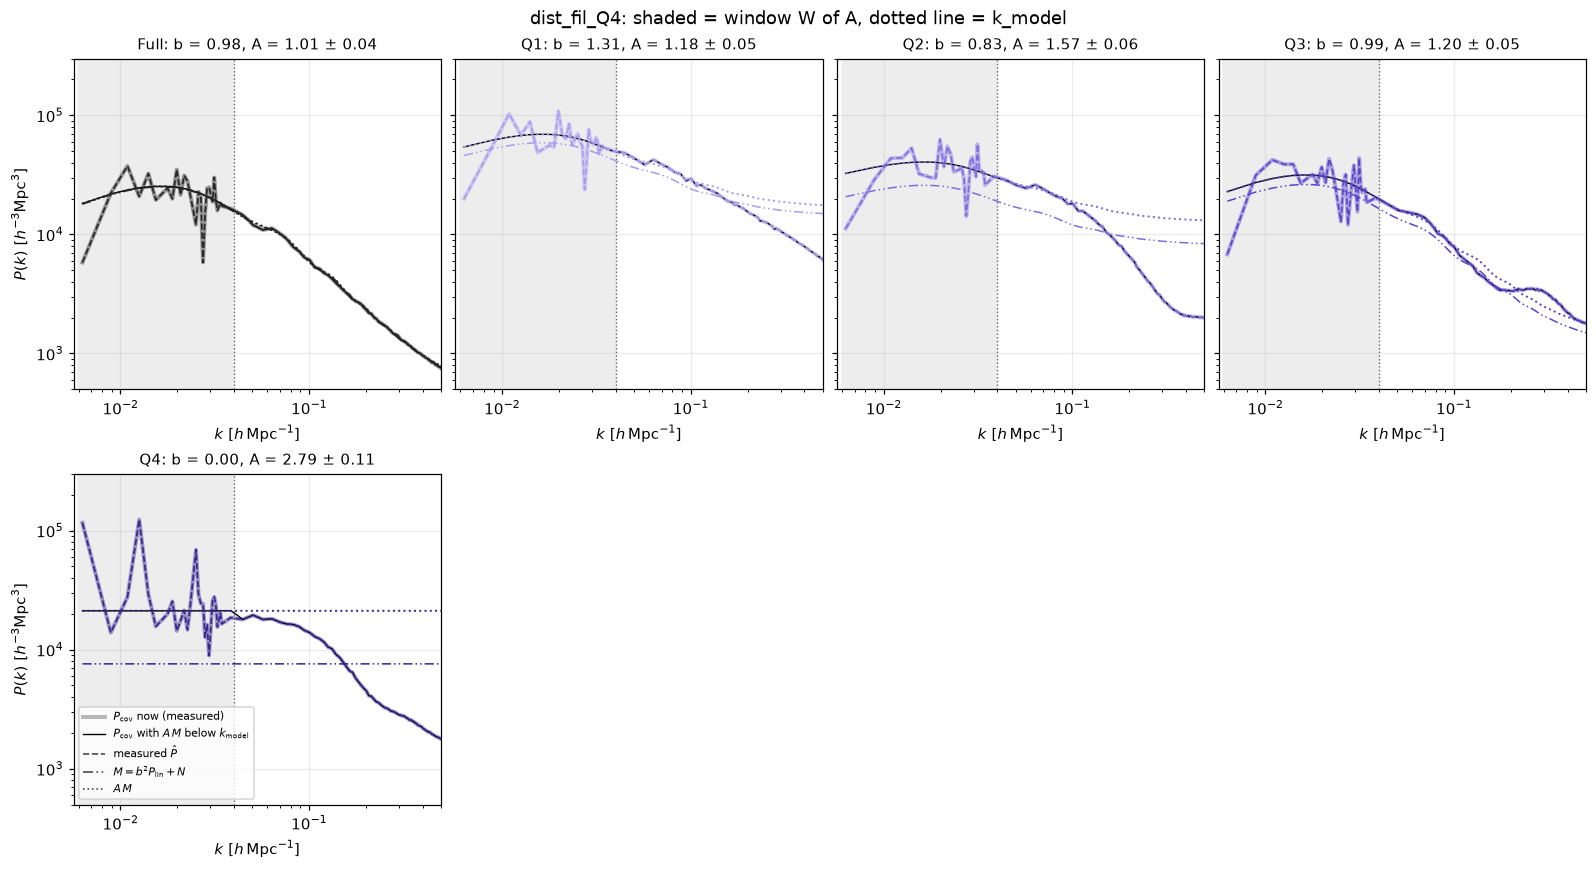

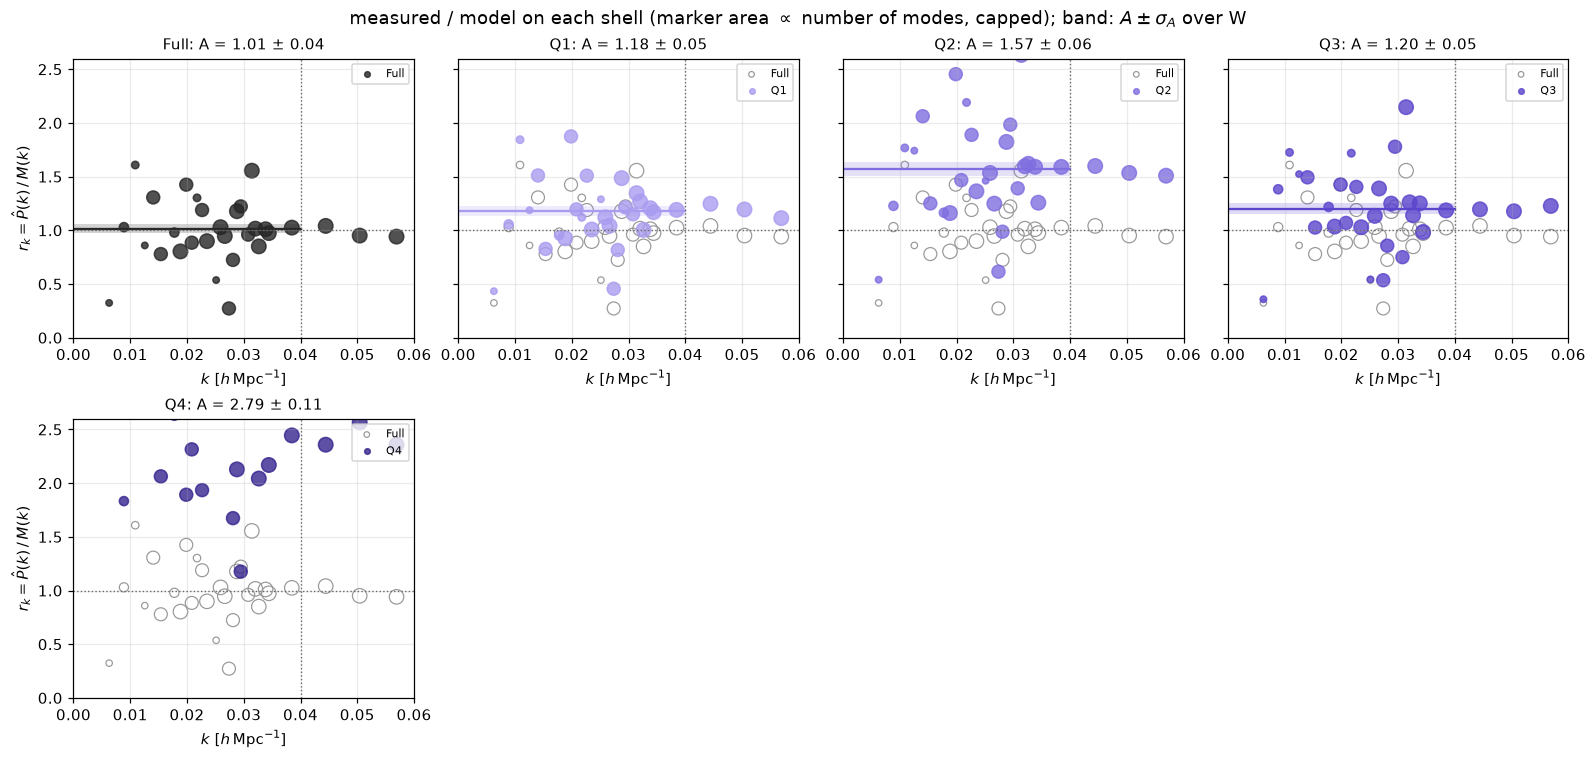

In [3]:
from matplotlib.lines import Line2D
k_modes, _ = bf.lattice_mode_counts(spec['L'], kmax_cov)    # the box's modes |k| = 2 pi |n| / L
dash_dot2 = (0, (6, 2, 1, 2, 1, 2))
fig, axP = panel_grid(len(check_samples), size=(3.6, 3.9), sharex=True, sharey=True, layout='constrained')
axP = axP[:, 0]
for a, lab in zip(axP, check_samples):
    Lw = low[lab]; i, b, c = Lw['i'], Lw['b'], SCOL[lab]
    M = lambda x: b**2 * Plin(x) + Lw['N']
    a.axvspan(max(A_window[0], k_modes[0] * 0.95), A_window[1], color='0.93', zorder=0)
    a.axvline(k_model, color='0.4', ls=':', lw=0.9)
    a.loglog(k_modes, bf.spectrum_for_cov(spec, i, i, b, b, lin, k_modes)[0], color=c, lw=2.6, alpha=0.45)
    a.loglog(k_modes, bf.spectrum_for_cov(spec_A, i, i, b, b, lin, k_modes)[0], color='k', lw=0.9)
    a.loglog(kk, spec['P'][i, i], color=c, ls='--', lw=1.1)
    a.loglog(k_modes, M(k_modes), color=c, ls=dash_dot2, lw=1)
    a.loglog(k_modes, Lw['A'] * M(k_modes), color=c, ls=':', lw=1.3)
    a.set_title(f"{lab}: b = {b:.2f}, A = {Lw['A']:.2f} ± {Lw['sA']:.2f}", fontsize=10)
    a.set_xlabel(r'$k\ [h\,{\rm Mpc}^{-1}]$')
axP[0].set_xlim(0.9 * k_modes[0], 0.5); axP[0].set_ylim(5e2, 3e5)
for a in axP[::MAX_COLS]:
    a.set_ylabel(r'$P(k)\ [h^{-3}{\rm Mpc}^3]$')
thin = dict(color='0.3', lw=1.1)
axP[-1].legend(handles=[Line2D([], [], color='0.4', lw=2.6, alpha=0.45, label=r'$P_{\rm cov}$ now (measured)'),
                        Line2D([], [], color='k', lw=0.9, label=r'$P_{\rm cov}$ with $A\,M$ below $k_{\rm model}$'),
                        Line2D([], [], **thin, ls='--', label=r'measured $\hat P$'),
                        Line2D([], [], **thin, ls=dash_dot2, label=r'$M=b^2P_{\rm lin}+N$'),
                        Line2D([], [], **thin, ls=':', label=r'$A\,M$')], fontsize=7, loc='lower left')
fig.suptitle(f'{split_name}: shaded = window W of A, dotted line = k_model')
plt.show()

# second figure: the ratio r_k = P / M on the low-k shells, with A over W
k_show = 0.06
ms = kk <= k_show
size = np.clip(3 * nm, 6, 90)                               # marker area: 3 x number of modes, capped
fig, axR = panel_grid(len(check_samples), size=(3.6, 3.4), sharex=True, sharey=True, layout='constrained')
axR = axR[:, 0]
for a, lab in zip(axR, check_samples):
    Lw = low[lab]; c = SCOL[lab]
    if lab != 'Full' and 'Full' in low:
        a.scatter(kk[ms], low['Full']['r'][ms], s=size[ms], facecolors='none', edgecolors='0.6', lw=0.8, label='Full')
    a.scatter(kk[ms], Lw['r'][ms], s=size[ms], color=c, alpha=0.8, label=lab)
    a.fill_between(A_window, Lw['A'] - Lw['sA'], Lw['A'] + Lw['sA'], color=c, alpha=0.2, lw=0)
    a.plot(A_window, [Lw['A']] * 2, color=c, lw=1.5)
    a.axhline(1, color='0.4', ls=':', lw=0.9); a.axvline(k_model, color='0.4', ls=':', lw=0.9)
    a.set_title(f"{lab}: A = {Lw['A']:.2f} ± {Lw['sA']:.2f}", fontsize=10)
    a.set_xlabel(r'$k\ [h\,{\rm Mpc}^{-1}]$'); a.legend(fontsize=7, loc='upper right', markerscale=0.5)
axR[0].set_xlim(0, k_show); axR[0].set_ylim(0, 2.6)
for a in axR[::MAX_COLS]:
    a.set_ylabel(r'$r_k=\hat P(k)\,/\,M(k)$')
fig.suptitle(r'measured / model on each shell (marker area $\propto$ number of modes, capped); band: $A\pm\sigma_A$ over W')
plt.show()

## 3. The fits with both covariances

For each sample and covariance: the α fit (Gaussian Σ prior) with its 68% interval, the Σ fit (flat prior
`Sigma_free`) with the Δχ² = 1 interval of its profile χ²(Σ), and the Gaussian peak fit (width w and its interval), all
with the functions of `desilike_fits` section 2. The table gives both rows and, below them, the shifts (A model −
measured): `dalpha/sigma_alpha` = Δα in units of the half-width σ_α of the measured interval, `dSigma` = ΔΣ and `dw` = Δw in h⁻¹Mpc. `open` / `edge`: the
interval reaches the edge of the α prior / of `Sigma_free` or `peak_w_range`. The figure shows the three quantities
per sample: open markers with the measured spectrum, filled with the A model.

Full       measured  done (12 s)
Full       A model   done (24 s)
Q1         measured  done (34 s)
Q1         A model   done (44 s)
Q2         measured  done (55 s)
Q2         A model   done (66 s)
Q3         measured  done (78 s)
Q3         A model   done (90 s)
Q4         measured  done (104 s)
Q4         A model   done (116 s)

sample    covariance | alpha [68%]               | Sigma [68%]           | w [68%]               
-----------------------------------------------------------------------------------------------
Full      measured   | 0.9777 [0.9596, 0.9969]   | 6.26 [2.94, 9.97]     | 11.33 [9.20, 14.64]   
Full      A model    | 0.9777 [0.9596, 0.9969]   | 6.26 [2.94, 9.95]     | 11.33 [9.20, 14.64]   
          shift      | dalpha/sigma_alpha = +0.00| dSigma = -0.01        | dw = -0.00            
Q1        measured   | 0.9839 [0.9580, 1.0123]   | 0.07 [edge, 6.61]     | 8.24 [6.36, 11.40]    
Q1        A model    | 0.9839 [0.9580, 1.0123]   | 0.08 [edge, 6.62]     | 8.24 [

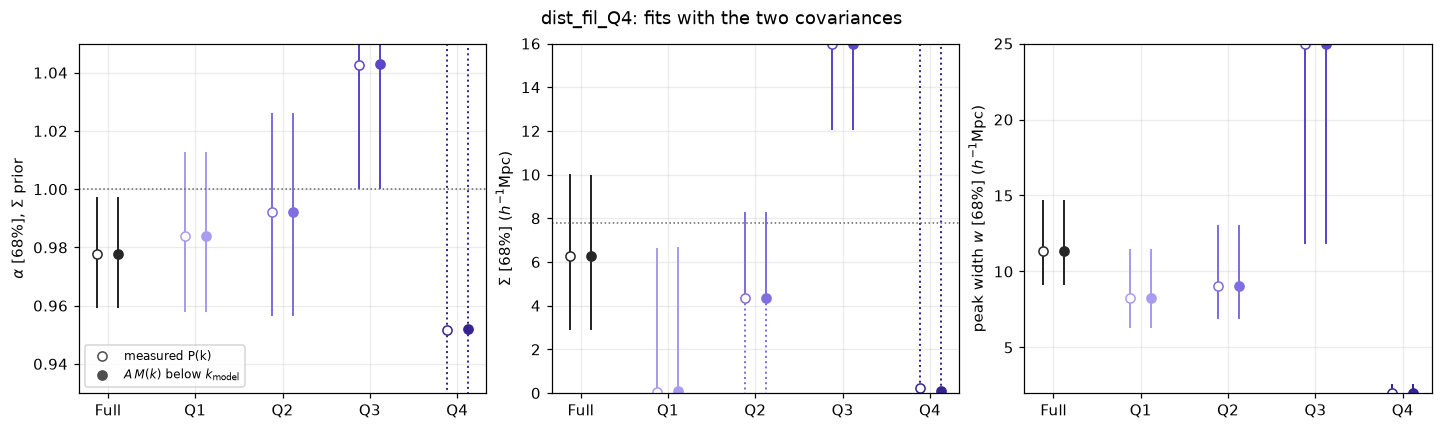

In [4]:
from matplotlib.lines import Line2D

def fit_three(d):
    # alpha fit with interval, Sigma fit with its profile, Gaussian peak fit (functions of desilike_fits section 2)
    f_a = desilike_fit(desilike_lik(d, 'gauss')[0], interval=True)
    lik_S = desilike_lik(d, 'flat')[0]; f_S = desilike_fit(lik_S)
    pS = sigma_profile(lik_S, f_S['pars']['sigmaper'])
    g = gauss_peak(d)
    return dict(alpha=f_a['pars']['qiso'], alpha_iv=(f_a['lo'], f_a['hi']), Sigma=f_S['pars']['sigmaper'],
                Sigma_iv=(pS['lo'], pS['hi']), w=g['w'], w_iv=g['w_iv'])

fits = {c: {} for c in COVS}
t0 = time.time()
for lab in check_samples:
    for c in COVS:
        fits[c][lab] = fit_three(dat[c][lab])
        print(f"{lab:<10} {c:<9} done ({time.time() - t0:.0f} s)")

iv = lambda x, lo, hi, nd, edge: f"{x:.{nd}f} [" + ", ".join(edge if not np.isfinite(v) else f"{v:.{nd}f}"
                                                              for v in (lo, hi)) + "]"
print(f"\n{'sample':<10}{'covariance':<11}| {'alpha [68%]':<26}| {'Sigma [68%]':<22}| {'w [68%]':<22}")
print('-' * 95)
for lab in check_samples:
    for c in COVS:
        F = fits[c][lab]
        print(f"{lab:<10}{c:<11}| {iv(F['alpha'], *F['alpha_iv'], 4, 'open'):<26}| "
              f"{iv(F['Sigma'], *F['Sigma_iv'], 2, 'edge'):<22}| {iv(F['w'], *F['w_iv'], 2, 'edge'):<22}")
    F0, F1 = fits['measured'][lab], fits['A model'][lab]
    s_a = 0.5 * (F0['alpha_iv'][1] - F0['alpha_iv'][0])          # half-width of the measured alpha interval
    sh_a = "dalpha/sigma_alpha = %+.2f" % ((F1['alpha'] - F0['alpha']) / s_a)
    sh_S = "dSigma = %+.2f" % (F1['Sigma'] - F0['Sigma'])
    sh_w = "dw = %+.2f" % (F1['w'] - F0['w'])
    print(f"{'':<10}{'shift':<11}| {sh_a:<26}| {sh_S:<22}| {sh_w:<22}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), layout='constrained')
x = np.arange(len(check_samples))
edges_of = {'alpha': (0.8, 1.2), 'Sigma': Sigma_free, 'w': peak_w_range}
for a, (q, lab_) in zip(axes, (('alpha', r'$\alpha$ [68%], $\Sigma$ prior'), ('Sigma', r'$\Sigma$ [68%] ($h^{-1}$Mpc)'),
                               ('w', r'peak width $w$ [68%] ($h^{-1}$Mpc)'))):
    for dx, c, filled in ((-0.12, 'measured', False), (0.12, 'A model', True)):
        for j, lab in enumerate(check_samples):
            F = fits[c][lab]; col = SCOL[lab]
            lo, hi = F[q + '_iv']
            for v, edge in ((lo, edges_of[q][0]), (hi, edges_of[q][1])):   # a side at the edge: dotted to it
                a.plot([x[j] + dx] * 2, [F[q], v if np.isfinite(v) else edge], color=col,
                       ls='-' if np.isfinite(v) else ':', lw=1.3)
            a.plot(x[j] + dx, F[q], 'o', ms=6, color=col, mfc=col if filled else 'white')
    if q == 'Sigma':
        a.axhline(Sigma_th, color='0.4', ls=':', lw=1)
    if q == 'alpha':
        a.axhline(1, color='0.4', ls=':', lw=1)
    a.set_xticks(x); a.set_xticklabels(check_samples); a.set_ylabel(lab_)
axes[0].set_ylim(0.93, 1.05); axes[1].set_ylim(*Sigma_free); axes[2].set_ylim(*peak_w_range)
axes[0].legend(handles=[Line2D([], [], marker='o', ls='', color='0.3', mfc='white', label='measured P(k)'),
                        Line2D([], [], marker='o', ls='', color='0.3', label=r'$A\,M(k)$ below $k_{\rm model}$')],
               fontsize=8, loc='lower left')
fig.suptitle(f'{split_name}: fits with the two covariances')
plt.show()